In [2]:
import pandas as pd

df = pd.read_csv('cleaned_online_retail.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df.shape)

(392692, 9)


In [3]:
print("Dataset shape:", df.shape)

df.info()

df.describe()

Dataset shape: (392692, 9)
<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  int64         
 1   StockCode    392692 non-null  str           
 2   Description  392692 non-null  str           
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  str           
 8   TotalAmount  392692 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 27.0 MB


,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalAmount
count,392692.000000,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,560590.875047,13.119702,2011-07-10 19:13:07.771892,3.125914,15287.843865,22.631500
min,536365.000000,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,549234.000000,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,561874.000000,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,572061.000000,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,581587.000000,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,13087.063759,180.492832,NaN,22.241836,1713.539549,311.099224


In [4]:
print("Unique customers:", df['CustomerID'].nunique())
print("Unique invoices:", df['InvoiceNo'].nunique())
print("Unique products:", df['StockCode'].nunique())
print("Unique descriptions:", df['Description'].nunique())
print("Unique countries:", df['Country'].nunique())

Unique customers: 4338
Unique invoices: 18532
Unique products: 3665
Unique descriptions: 3877
Unique countries: 37


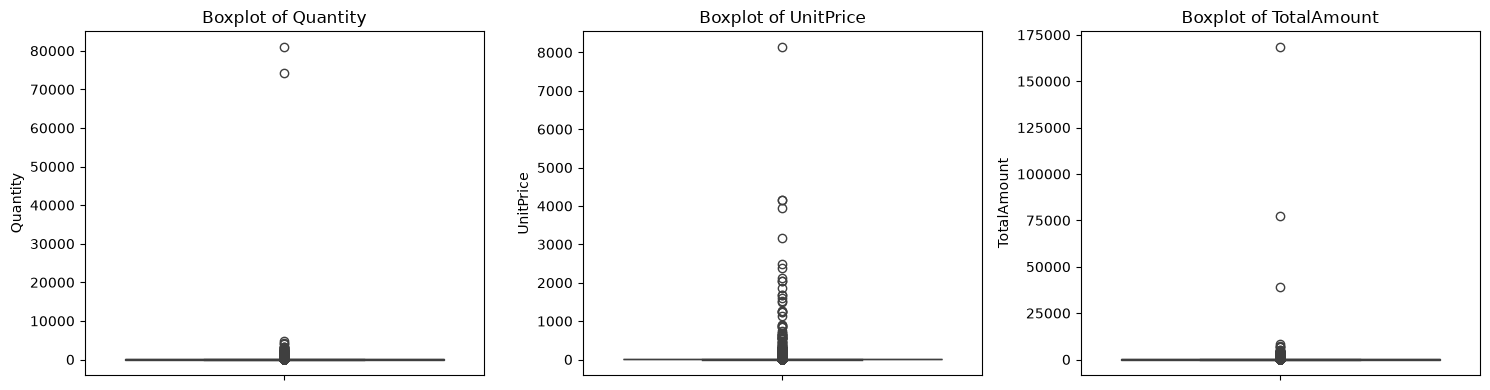

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 4))

for i, col in enumerate(['Quantity', 'UnitPrice', 'TotalAmount'], 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [6]:
cols = ['Quantity', 'UnitPrice', 'TotalAmount']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outlier count:", len(outliers))
    print("Outlier percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")


Column: Quantity
Q1: 2.0
Q3: 12.0
IQR: 10.0
Lower bound: -13.0
Upper bound: 27.0
Outlier count: 25616
Outlier percentage: 6.52 %

Column: UnitPrice
Q1: 1.25
Q3: 3.75
IQR: 2.5
Lower bound: -2.5
Upper bound: 7.5
Outlier count: 34112
Outlier percentage: 8.69 %

Column: TotalAmount
Q1: 4.949999999999999
Q3: 19.8
IQR: 14.850000000000001
Lower bound: -17.325000000000003
Upper bound: 42.075
Outlier count: 31231
Outlier percentage: 7.95 %


In [7]:
df.nlargest(10, 'Quantity')[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'InvoiceDate',
     'CustomerID', 'TotalAmount']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,TotalAmount
392226,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446.0,168469.60
36521,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346.0,77183.60
304654,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27 12:26:00,12901.0,1008.00
141558,554868,22197,SMALL POPCORN HOLDER,4300,0.72,2011-05-27 10:52:00,13135.0,3096.00
60687,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,2011-02-22 10:43:00,18087.0,3202.92
186665,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,2011-07-19 17:04:00,14609.0,191.16
32199,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-01-11 12:55:00,15749.0,6539.40
108204,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-04-18 13:20:00,15749.0,6539.40
314508,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,2011-11-02 11:24:00,16308.0,960.00
3591,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,2010-12-02 17:38:00,16754.0,518.40


In [8]:
df.nlargest(10, 'UnitPrice')[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'InvoiceDate',
     'CustomerID', 'TotalAmount']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,TotalAmount
116868,551697,POST,POSTAGE,1,8142.75,2011-05-03 13:46:00,16029.0,8142.75
305341,573077,M,Manual,1,4161.06,2011-10-27 14:13:00,12536.0,4161.06
305365,573080,M,Manual,1,4161.06,2011-10-27 14:20:00,12536.0,4161.06
292020,571751,M,Manual,1,3949.32,2011-10-19 11:18:00,12744.0,3949.32
266726,569382,M,Manual,1,3155.95,2011-10-03 16:44:00,15502.0,3155.95
206437,562946,M,Manual,1,2500.00,2011-08-11 09:38:00,15581.0,2500.00
95757,548813,M,Manual,1,2382.92,2011-04-04 13:03:00,12744.0,2382.92
292021,571751,M,Manual,1,2118.74,2011-10-19 11:18:00,12744.0,2118.74
95760,548820,M,Manual,1,2053.07,2011-04-04 13:04:00,12744.0,2053.07
241495,566927,M,Manual,1,2033.10,2011-09-15 15:20:00,17846.0,2033.10


In [9]:
df.nlargest(10, 'TotalAmount')[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'InvoiceDate',
     'CustomerID', 'TotalAmount']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,TotalAmount
392226,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446.0,168469.60
36521,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346.0,77183.60
153588,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,2011-06-10 15:28:00,15098.0,38970.00
116868,551697,POST,POSTAGE,1,8142.75,2011-05-03 13:46:00,16029.0,8142.75
246041,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,2011-09-20 11:05:00,17450.0,7144.72
32199,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-01-11 12:55:00,15749.0,6539.40
108204,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-04-18 13:20:00,15749.0,6539.40
304623,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,2011-10-27 12:11:00,14646.0,4992.00
32197,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,2011-01-11 12:55:00,15749.0,4921.50
108200,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,2011-04-18 13:20:00,15749.0,4632.00


In [10]:
cols = ['Quantity', 'UnitPrice', 'TotalAmount']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    mask = df[col] > upper_bound

    print(f"\n{col}")
    print("Outlier rows:", mask.sum())
    print("Outlier rows ka revenue:",
          round(df.loc[mask, 'TotalAmount'].sum(), 2))
    print("Outlier rows ka revenue percentage:",
          round(df.loc[mask, 'TotalAmount'].sum()
                / df['TotalAmount'].sum() * 100, 2), "%")


Quantity
Outlier rows: 25616
Outlier rows ka revenue: 3560614.54
Outlier rows ka revenue percentage: 40.06 %

UnitPrice
Outlier rows: 34112
Outlier rows ka revenue: 1242384.59
Outlier rows ka revenue percentage: 13.98 %

TotalAmount
Outlier rows: 31231
Outlier rows ka revenue: 4513614.39
Outlier rows ka revenue percentage: 50.79 %


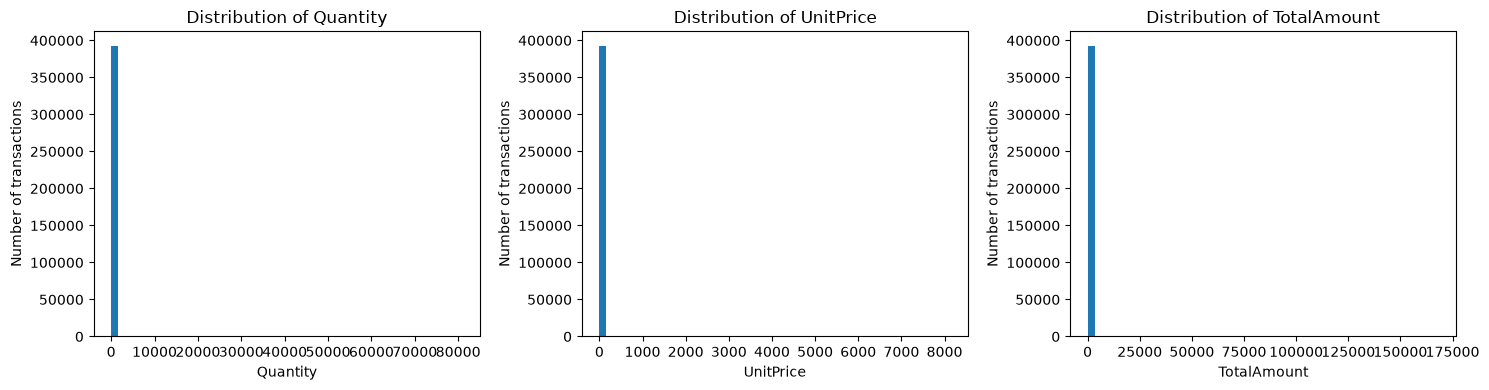

In [11]:
import matplotlib.pyplot as plt

cols = ['Quantity', 'UnitPrice', 'TotalAmount']

plt.figure(figsize=(15, 4))

for i, col in enumerate(cols, 1):
    plt.subplot(1, 3, i)
    plt.hist(df[col], bins=50)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of transactions')

plt.tight_layout()
plt.show()

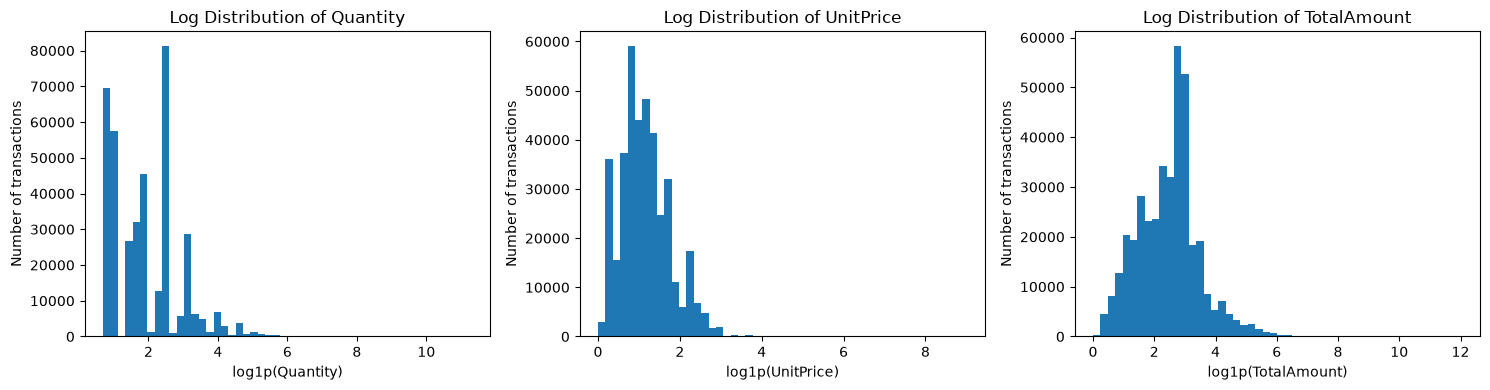

In [12]:
import numpy as np
import matplotlib.pyplot as plt

cols = ['Quantity', 'UnitPrice', 'TotalAmount']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    ax.hist(np.log1p(df[col]), bins=50)
    ax.set_title(f'Log Distribution of {col}')
    ax.set_xlabel(f'log1p({col})')
    ax.set_ylabel('Number of transactions')

plt.tight_layout()
plt.show()

In [13]:
top_quantity = (
    df.groupby(['StockCode', 'Description'])['Quantity']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_quantity

StockCode  Description                       
23843      PAPER CRAFT , LITTLE BIRDIE           80995
23166      MEDIUM CERAMIC TOP STORAGE JAR        77916
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
85099B     JUMBO BAG RED RETROSPOT               46078
85123A     WHITE HANGING HEART T-LIGHT HOLDER    36706
84879      ASSORTED COLOUR BIRD ORNAMENT         35263
21212      PACK OF 72 RETROSPOT CAKE CASES       33670
22197      POPCORN HOLDER                        30919
23084      RABBIT NIGHT LIGHT                    27153
22492      MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

In [14]:
top_revenue = (
    df.groupby(['StockCode', 'Description'])['TotalAmount']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_revenue

StockCode  Description                       
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
22423      REGENCY CAKESTAND 3 TIER              142264.75
85123A     WHITE HANGING HEART T-LIGHT HOLDER    100392.10
85099B     JUMBO BAG RED RETROSPOT                85040.54
23166      MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POST       POSTAGE                                77803.96
47566      PARTY BUNTING                          68785.23
84879      ASSORTED COLOUR BIRD ORNAMENT          56413.03
M          Manual                                 53419.93
23084      RABBIT NIGHT LIGHT                     51251.24
Name: TotalAmount, dtype: float64

In [15]:
country_summary = (
    df.groupby('Country')
      .agg(
          TotalOrders=('InvoiceNo', 'nunique'),
          TotalRevenue=('TotalAmount', 'sum'),
          TotalCustomers=('CustomerID', 'nunique')
      )
      .sort_values('TotalRevenue', ascending=False)
)

country_summary.head(10)

,TotalOrders,TotalRevenue,TotalCustomers
Country,,,
United Kingdom,16646,7285024.644,3920
Netherlands,94,285446.340,9
EIRE,260,265262.460,3
Germany,457,228678.400,94
France,389,208934.310,87
Australia,57,138453.810,9
Spain,90,61558.560,30
Switzerland,51,56443.950,21
Belgium,98,41196.340,25


In [16]:
uk_revenue = df.loc[
    df['Country'] == 'United Kingdom',
    'TotalAmount'
].sum()

total_revenue = df['TotalAmount'].sum()

uk_percentage = (uk_revenue / total_revenue) * 100

print("UK Revenue:", round(uk_revenue, 2))
print("Total Revenue:", round(total_revenue, 2))
print("UK Revenue Contribution:", round(uk_percentage, 2), "%")

UK Revenue: 7285024.64
Total Revenue: 8887208.89
UK Revenue Contribution: 81.97 %


In [17]:
monthly_revenue = (
    df.set_index('InvoiceDate')
      .resample('MS')['TotalAmount']
      .sum()
)

monthly_revenue

InvoiceDate
2010-12-01     570422.730
2011-01-01     568101.310
2011-02-01     446084.920
2011-03-01     594081.760
2011-04-01     468374.331
2011-05-01     677355.150
2011-06-01     660046.050
2011-07-01     598962.901
2011-08-01     644051.040
2011-09-01     950690.202
2011-10-01    1035642.450
2011-11-01    1156205.610
2011-12-01     517190.440
Freq: MS, Name: TotalAmount, dtype: float64

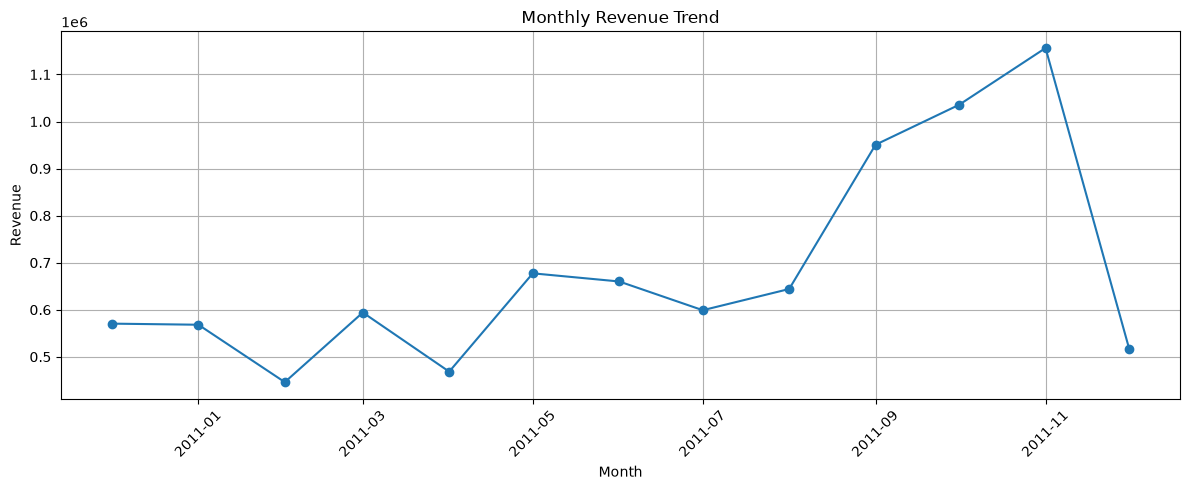

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue.index, monthly_revenue.values, marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
customer_spending = (
    df.groupby('CustomerID')['TotalAmount']
      .sum()
      .sort_values(ascending=False)
)

customer_spending.head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalAmount, dtype: float64

In [20]:
customer_frequency = (
    df.groupby('CustomerID')['InvoiceNo']
      .nunique()
      .sort_values(ascending=False)
)

customer_frequency.head(10)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

In [21]:
print("Last transaction date:", df['InvoiceDate'].max())

Last transaction date: 2011-12-09 12:50:00


In [22]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

customer_recency = (
    df.groupby('CustomerID')['InvoiceDate']
      .max()
      .apply(lambda date: (reference_date - date).days)
      .sort_values()
)

customer_recency.head(10)

CustomerID
17364.0    1
12433.0    1
13599.0    1
13536.0    1
16933.0    1
17581.0    1
15898.0    1
16892.0    1
17644.0    1
15910.0    1
Name: InvoiceDate, dtype: int64

In [23]:
print("Minimum Recency:", customer_recency.min())
print("Maximum Recency:", customer_recency.max())
print("Customers with Recency = 1:", (customer_recency == 1).sum())
print("Total customers:", customer_recency.count())

Minimum Recency: 1
Maximum Recency: 374
Customers with Recency = 1: 93
Total customers: 4338


In [24]:
rfm = pd.concat(
    [
        customer_recency.rename('Recency'),
        customer_frequency.rename('Frequency'),
        customer_spending.rename('Monetary')
    ],
    axis=1
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
17364.0,1,11,4462.68
12433.0,1,7,13375.87
13599.0,1,21,5149.92
13536.0,1,7,3444.39
16933.0,1,2,563.23


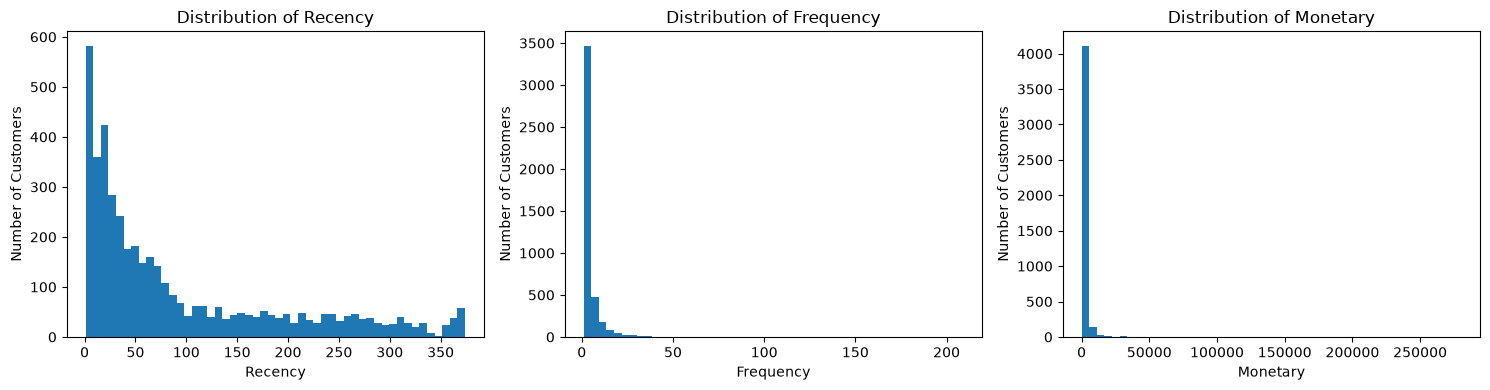

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    ax.hist(rfm[col], bins=50)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

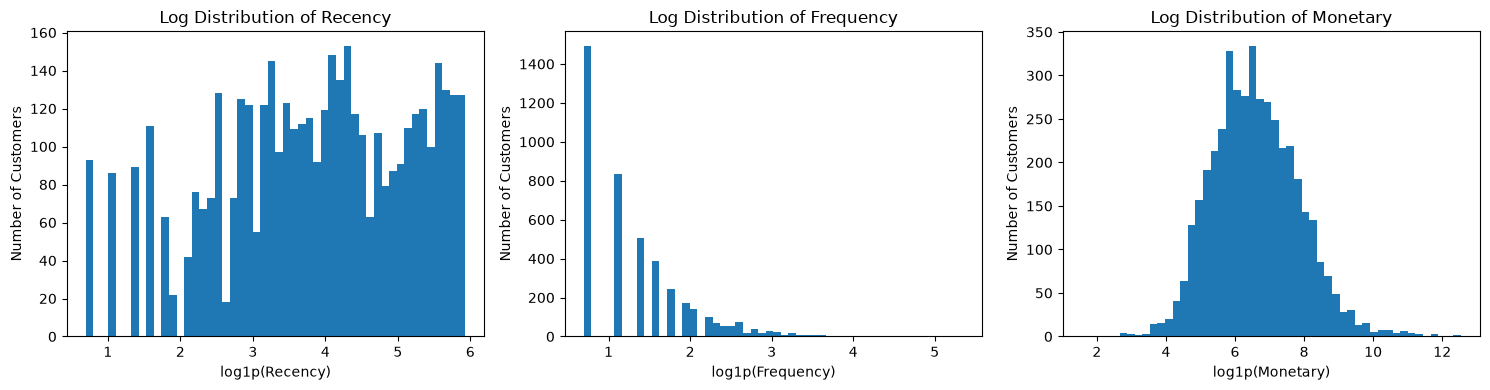

In [27]:
import numpy as np

rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, rfm_log.columns):
    ax.hist(rfm_log[col], bins=50)
    ax.set_title(f'Log Distribution of {col}')
    ax.set_xlabel(f'log1p({col})')
    ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

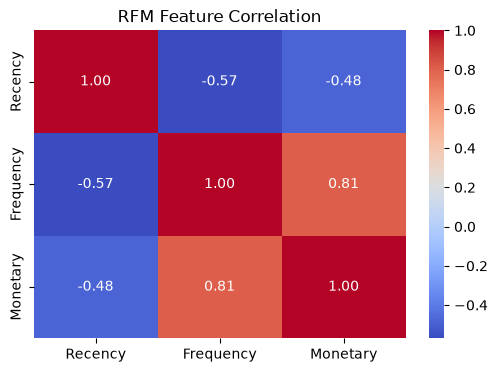

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = rfm_log.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('RFM Feature Correlation')
plt.show()

In [29]:
one_time = (rfm['Frequency'] == 1).sum()
repeat = (rfm['Frequency'] > 1).sum()

total = len(rfm)

print("One-time customers:", one_time)
print("Repeat customers:", repeat)

print("One-time customers (%):", round(one_time / total * 100, 2))
print("Repeat customers (%):", round(repeat / total * 100, 2))

One-time customers: 1493
Repeat customers: 2845
One-time customers (%): 34.42
Repeat customers (%): 65.58


In [30]:
customer_revenue = rfm['Monetary'].sort_values(ascending=False)

top_20_count = int(len(customer_revenue) * 0.20)

top_20_revenue = customer_revenue.head(top_20_count).sum()
total_revenue = customer_revenue.sum()

percentage = (top_20_revenue / total_revenue) * 100

print("Total customers:", len(customer_revenue))
print("Top 20% customers:", top_20_count)
print("Revenue contribution of top 20% customers:", round(percentage, 2), "%")

Total customers: 4338
Top 20% customers: 867
Revenue contribution of top 20% customers: 74.66 %
